In [ ]:
!pip install -q torch torchvision open_clip_torch timm

import torch
import torch.nn as nn
import requests
from io import BytesIO
from PIL import Image
import open_clip
from torchvision import datasets

model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32-quickgelu", pretrained="openai")
model = model.visual
model.eval()

test_set = datasets.CIFAR100(root="./data", train=False, download=True, transform=preprocess)

print("Setup complete. Test set size:", len(test_set))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.1 MB/s eta 0:00:00


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

100%|██████████| 169M/169M [33:15<00:00, 84.7kB/s]


Setup complete. Test set size: 10000


In [ ]:
pip install torch torchvision open_clip_torch timm

In [ ]:
import torch
import open_clip

model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32-quickgelu", pretrained="openai")
model = model.visual
model.eval()

dummy_image = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    x = model.conv1(dummy_image)
    print("After conv1 (patch embedding):", x.shape)

After conv1 (patch embedding): torch.Size([1, 768, 7, 7])


In [ ]:
x = x.reshape(x.shape[0], x.shape[1], -1)   # step 1: (1, 768, 49)
print(x.shape)

torch.Size([1, 768, 49])


In [ ]:
x = x.permute(0, 2, 1)                       # step 2: swap dims 1 and 2
print(x.shape)

torch.Size([1, 49, 768])


In [ ]:
dino = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14")
dino.eval()

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 145MB/s]


DinoVisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(14, 14), stride=(14, 14))
    (norm): Identity()
  )
  (blocks): ModuleList(
    (0-11): 12 x NestedTensorBlock(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): MemEffAttention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (drop_path1): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
      (ls2): LayerScale()
      (drop_path2): Identity()
    )
  )
  (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

In [ ]:
dummy_image = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    features = dino.forward_features(dummy_image)

print(features.keys())
print(features["x_norm_patchtokens"].shape)

dict_keys(['x_norm_clstoken', 'x_norm_regtokens', 'x_norm_patchtokens', 'x_prenorm', 'masks'])
torch.Size([1, 256, 384])


In [ ]:
import torch

def prune_tokens(tokens, keep_ratio):
    b, n, d = tokens.shape
    k = round(n * keep_ratio)

    norms = tokens.norm(dim=-1)  # (b, n)

    top_idx = norms.topk(k, dim=-1).indices  # (b, k)

    kept = torch.gather(tokens, 1, top_idx.unsqueeze(-1).expand(-1, -1, d))  # (b, k, d)

    return kept


dummy = torch.randn(1, 49, 768)
result = prune_tokens(dummy, keep_ratio=0.5)
print(result.shape)

torch.Size([1, 24, 768])


In [ ]:
import torch

dummy = torch.randn(1, 10, 8) * 0.1

big_token_indices = [2, 5, 8]
dummy[0, big_token_indices, :] = 100.0

result = prune_tokens(dummy, keep_ratio=0.3)  # 10 * 0.3 = 3 tokens kept
print(result.shape)

print(result.norm(dim=-1))

torch.Size([1, 3, 8])
tensor([[282.8427, 282.8427, 282.8427]])


In [ ]:
def prune_tokens_with_context(tokens, keep_ratio, context_frac=0.25):
    b, n, d = tokens.shape
    k_total = round(n * keep_ratio)
    k_context = max(1, round(k_total * context_frac))
    k_dominant = k_total - k_context

    norms = tokens.norm(dim=-1)
    order = norms.argsort(dim=-1, descending=True)

    dominant_idx = order[:, :k_dominant]
    rest_idx = order[:, k_dominant:]

    dominant = torch.gather(tokens, 1, dominant_idx.unsqueeze(-1).expand(-1, -1, d))
    rest = torch.gather(tokens, 1, rest_idx.unsqueeze(-1).expand(-1, -1, d))

    chunks = torch.chunk(rest, k_context, dim=1)
    context = torch.stack([c.mean(dim=1) for c in chunks], dim=1)

    return torch.cat([dominant, context], dim=1)


dummy = torch.randn(1, 10, 8) * 0.1
big_token_indices = [2, 5, 8]
dummy[0, big_token_indices, :] = 100.0

result = prune_tokens_with_context(dummy, keep_ratio=0.3)
print(result.shape)
print(result.norm(dim=-1))

torch.Size([1, 3, 8])
tensor([[282.8427, 282.8427,  35.3225]])


In [ ]:
model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32-quickgelu", pretrained="openai")
model = model.visual
model.eval()

dummy_image = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    x = model.conv1(dummy_image)
    x = x.reshape(x.shape[0], x.shape[1], -1)
    x = x.permute(0, 2, 1)

print("Real CLIP tokens shape:", x.shape)

compressed = prune_tokens_with_context(x, keep_ratio=0.5)
print("Compressed shape:", compressed.shape)
print(compressed.norm(dim=-1))

Real CLIP tokens shape: torch.Size([1, 49, 768])
Compressed shape: torch.Size([1, 24, 768])
tensor([[25.0000, 24.7660, 24.7269, 24.7018, 24.6961, 24.6708, 24.5035, 24.4594,
         24.4297, 24.2276, 24.1289, 24.1098, 24.0861, 24.0642, 23.9864, 23.8853,
         23.6352, 23.6209,  9.4650,  8.9778,  9.2896,  8.6113,  8.7098, 20.3723]])


In [ ]:
from PIL import Image
import requests

url = "https://rendezvous-dubai.com/wp-content/uploads/2023/04/G-class-Rendez-vous-dubai-1.jpg"
image = Image.open(requests.get(url, stream=True).raw).convert("RGB")

image_tensor = preprocess(image).unsqueeze(0)  # uses CLIP's real preprocessing
print("Preprocessed shape:", image_tensor.shape)

with torch.no_grad():
    x = model.conv1(image_tensor)
    x = x.reshape(x.shape[0], x.shape[1], -1)
    x = x.permute(0, 2, 1)

print("Token shape:", x.shape)
compressed = prune_tokens_with_context(x, keep_ratio=0.5)
print("Compressed shape:", compressed.shape)

Preprocessed shape: torch.Size([1, 3, 224, 224])
Token shape: torch.Size([1, 49, 768])
Compressed shape: torch.Size([1, 24, 768])


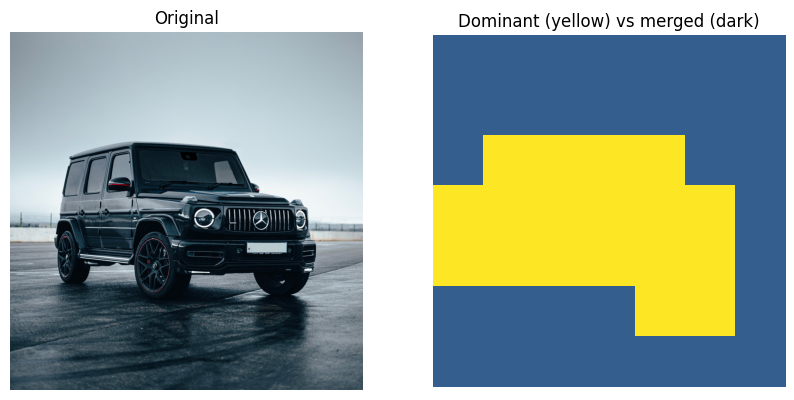

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

norms = x.norm(dim=-1)  # (1, 49)
order = norms.argsort(dim=-1, descending=True)

k_total = round(49 * 0.5)      # 24
k_context = round(k_total * 0.25)  # 6
k_dominant = k_total - k_context   # 18

dominant_idx = order[0, :k_dominant].tolist()
merged_idx = order[0, k_dominant:].tolist()

grid = np.zeros(49)
for i in dominant_idx:
    grid[i] = 1.0
for i in merged_idx:
    grid[i] = 0.3
grid = grid.reshape(7, 7)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(grid, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Dominant (yellow) vs merged (dark)")
axes[1].axis("off")
plt.show()

In [ ]:
import torch
import torch.nn as nn

class PerceiverResampler(nn.Module):
    def __init__(self, embed_dim, num_queries, num_heads=8):
        super().__init__()
        self.num_queries = num_queries

        self.queries = nn.Parameter(torch.randn(num_queries, embed_dim) * 0.02)

        self.attn = nn.MultiheadAttention(embed_dim, num_heads, batch_first=True)

    def forward(self, tokens):
        b = tokens.shape[0]

        q = self.queries.unsqueeze(0).expand(b, -1, -1)

        out, _ = self.attn(q, tokens, tokens)

        return out


resampler = PerceiverResampler(embed_dim=768, num_queries=12)
dummy = torch.randn(1, 49, 768)
result = resampler(dummy)
print(result.shape)

torch.Size([1, 12, 768])


In [ ]:
resampler = PerceiverResampler(embed_dim=768, num_queries=12)
dummy = torch.randn(1, 49, 768)

result = resampler(dummy)
loss = result.sum()
loss.backward()

print("Gradient exists:", resampler.queries.grad is not None)
print("Gradient shape:", resampler.queries.grad.shape)
print("Gradient sample:", resampler.queries.grad[0, :5])

Gradient exists: True
Gradient shape: torch.Size([12, 768])
Gradient sample: tensor([ 0.0213, -0.0094, -0.0476,  0.0156,  0.0022])


In [ ]:
class PerceiverDecoder(nn.Module):
    def __init__(self, embed_dim, num_output_tokens, num_heads=8):
        super().__init__()
        self.output_queries = nn.Parameter(torch.randn(num_output_tokens, embed_dim) * 0.02)
        self.attn = nn.MultiheadAttention(embed_dim, num_heads, batch_first=True)

    def forward(self, compressed_tokens):
        b = compressed_tokens.shape[0]
        q = self.output_queries.unsqueeze(0).expand(b, -1, -1)
        out, _ = self.attn(q, compressed_tokens, compressed_tokens)
        return out

In [ ]:
resampler = PerceiverResampler(embed_dim=768, num_queries=12)
decoder = PerceiverDecoder(embed_dim=768, num_output_tokens=49)

optimizer = torch.optim.Adam(
    list(resampler.parameters()) + list(decoder.parameters()),
    lr=1e-3
)

dummy = torch.randn(1, 49, 768)

for epoch in range(200):
    compressed = resampler(dummy)
    reconstructed = decoder(compressed)

    loss = ((reconstructed - dummy) ** 2).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 20 == 0:
        print(epoch, loss.item())

0 0.9972050189971924
20 0.9765082001686096
40 0.9763227105140686
60 0.976275622844696
80 0.976272463798523
100 0.9762716293334961
120 0.9762715697288513
140 0.9762714505195618
160 0.9762715697288513
180 0.9762714505195618


In [ ]:
from PIL import Image

In [ ]:
import requests
from io import BytesIO

urls = [
    "https://images.unsplash.com/photo-1518791841217-8f162f1e1131",  # cat
    "https://images.unsplash.com/photo-1543466835-00a7907e9de1",     # dog
    "https://images.unsplash.com/photo-1506744038136-46273834b3fb",  # mountain
    "https://images.unsplash.com/photo-1520250497591-112f2f40a3f4",  # forest
    "https://images.unsplash.com/photo-1494526585095-c41746248156",  # house
]

images = [Image.open(BytesIO(requests.get(u).content)).convert("RGB") for u in urls]

token_list = []
for img in images:
    img_tensor = preprocess(img).unsqueeze(0)
    with torch.no_grad():
        x = model.conv1(img_tensor)
        x = x.reshape(x.shape[0], x.shape[1], -1)
        x = x.permute(0, 2, 1)
    token_list.append(x)

real_tokens = torch.cat(token_list, dim=0)  # batch of 5 now
print(real_tokens.shape)

torch.Size([5, 49, 768])


In [ ]:
resampler = PerceiverResampler(embed_dim=768, num_queries=12)
decoder = PerceiverDecoder(embed_dim=768, num_output_tokens=49)

optimizer = torch.optim.Adam(
    list(resampler.parameters()) + list(decoder.parameters()),
    lr=1e-3
)

for epoch in range(200):
    compressed = resampler(real_tokens)
    reconstructed = decoder(compressed)

    loss = ((reconstructed - real_tokens) ** 2).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 20 == 0:
        print(epoch, loss.item())

0 1.2094347476959229
20 1.1376457214355469
40 1.1364104747772217
60 1.1363039016723633
80 1.1362898349761963
100 1.136451244354248
120 1.1362930536270142
140 1.1362888813018799
160 1.136288046836853
180 1.136287808418274


In [ ]:
baseline_pred = real_tokens.mean(dim=1, keepdim=True).expand(-1, 49, -1)
baseline_loss = ((baseline_pred - real_tokens) ** 2).mean()
print("Baseline (mean-token) loss:", baseline_loss.item())
print("Your trained model's loss:", 1.136)

Baseline (mean-token) loss: 1.1362876892089844
Your trained model's loss: 1.136


In [ ]:
compressed = resampler(real_tokens)

one_image_compressed = compressed[0]
pairwise_std = one_image_compressed.std(dim=0).mean()
print("Average std across the 12 output tokens:", pairwise_std.item())

print("Average std across original 49 tokens:", real_tokens[0].std(dim=0).mean().item())

Average std across the 12 output tokens: 0.0011856771307066083
Average std across original 49 tokens: 0.7993491291999817


In [ ]:
fresh_resampler = PerceiverResampler(embed_dim=768, num_queries=12)
init_std = fresh_resampler.queries.std(dim=0).mean()
print("Std across 12 queries at initialization:", init_std.item())

Std across 12 queries at initialization: 0.019789153710007668


In [ ]:
class PerceiverResampler(nn.Module):
    def __init__(self, embed_dim, num_queries, num_heads=8):
        super().__init__()
        self.num_queries = num_queries
        self.queries = nn.Parameter(torch.randn(num_queries, embed_dim))
        self.attn = nn.MultiheadAttention(embed_dim, num_heads, batch_first=True)
        self.norm_q = nn.LayerNorm(embed_dim)
        self.norm_kv = nn.LayerNorm(embed_dim)
        self.norm_out = nn.LayerNorm(embed_dim)

    def forward(self, tokens):
        b = tokens.shape[0]
        q = self.norm_q(self.queries).unsqueeze(0).expand(b, -1, -1)
        kv = self.norm_kv(tokens)
        out, _ = self.attn(q, kv, kv)
        return self.norm_out(out + q)

In [ ]:
print("Trained loss:", loss.item())
print("Baseline loss:", baseline_loss.item())
compressed = resampler(real_tokens)
print("Std across 12 output tokens:", compressed[0].std(dim=0).mean().item())

Trained loss: 1.1362876892089844
Baseline loss: 1.1362876892089844
Std across 12 output tokens: 0.0011856771307066083


In [ ]:
check_resampler = PerceiverResampler(embed_dim=768, num_queries=12)
print("Init std (no training yet):", check_resampler.queries.std(dim=0).mean().item())

Init std (no training yet): 0.9729859828948975


In [ ]:
resampler = PerceiverResampler(embed_dim=768, num_queries=12)
decoder = PerceiverDecoder(embed_dim=768, num_output_tokens=49)

optimizer = torch.optim.Adam(
    list(resampler.parameters()) + list(decoder.parameters()),
    lr=1e-3
)

for epoch in range(200):
    compressed = resampler(real_tokens)
    reconstructed = decoder(compressed)
    loss = ((reconstructed - real_tokens) ** 2).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 20 == 0:
        print(epoch, loss.item())

print("Final trained loss:", loss.item())
print("Baseline loss:", baseline_loss.item())
print("Std across 12 output tokens:", compressed[0].std(dim=0).mean().item())

0 1.2221629619598389
20 0.9835806488990784
40 0.4507487118244171
60 0.14621350169181824
80 0.050656553357839584
100 0.020841186866164207
120 0.00961915124207735
140 0.005067605525255203
160 0.002923212945461273
180 0.001960114808753133
Final trained loss: 0.0013073439477011561
Baseline loss: 1.1362876892089844
Std across 12 output tokens: 1.0487850904464722


In [ ]:
from torchvision import datasets

test_set = datasets.CIFAR100(root="./data", train=False, download=True, transform=preprocess)

print("Total images available:", len(test_set))
print("Number of classes:", len(test_set.classes))
print("Example classes:", test_set.classes[:10])

Total images available: 10000
Number of classes: 100
Example classes: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle']


In [ ]:
import torch

torch.manual_seed(42)

train_indices = torch.randperm(len(test_set))[:300]
train_subset = torch.utils.data.Subset(test_set, train_indices.tolist())

remaining = list(set(range(len(test_set))) - set(train_indices.tolist()))
eval_indices = torch.tensor(remaining)[torch.randperm(len(remaining))[:1000]]
eval_subset = torch.utils.data.Subset(test_set, eval_indices.tolist())

print("Train subset size:", len(train_subset))
print("Eval subset size:", len(eval_subset))

train_set_ids = set(train_indices.tolist())
eval_set_ids = set(eval_indices.tolist())
print("Overlap between train and eval:", len(train_set_ids & eval_set_ids))

Train subset size: 300
Eval subset size: 1000
Overlap between train and eval: 0


In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_subset, batch_size=32, shuffle=True)
eval_loader = DataLoader(eval_subset, batch_size=32, shuffle=False)

images, labels = next(iter(train_loader))
print("Batch of images shape:", images.shape)
print("Batch of labels shape:", labels.shape)
print("First few labels:", labels[:5])

Batch of images shape: torch.Size([32, 3, 224, 224])
Batch of labels shape: torch.Size([32])
First few labels: tensor([84, 45, 61, 63, 67])


In [ ]:
resampler = PerceiverResampler(embed_dim=768, num_queries=12)
decoder = PerceiverDecoder(embed_dim=768, num_output_tokens=49)

optimizer = torch.optim.Adam(
    list(resampler.parameters()) + list(decoder.parameters()),
    lr=1e-3
)

def get_tokens(images):
    with torch.no_grad():
        x = model.conv1(images)
        x = x.reshape(x.shape[0], x.shape[1], -1)
        x = x.permute(0, 2, 1)
    return x

num_epochs = 10
for epoch in range(num_epochs):
    epoch_losses = []
    for images, _ in train_loader:
        tokens = get_tokens(images)

        compressed = resampler(tokens)
        reconstructed = decoder(compressed)
        loss = ((reconstructed - tokens) ** 2).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_losses.append(loss.item())

    avg_loss = sum(epoch_losses) / len(epoch_losses)
    print(f"Epoch {epoch}: avg train loss = {avg_loss:.4f}")

Epoch 0: avg train loss = 0.3736
Epoch 1: avg train loss = 0.3535
Epoch 2: avg train loss = 0.3539
Epoch 3: avg train loss = 0.3471
Epoch 4: avg train loss = 0.3472
Epoch 5: avg train loss = 0.3429
Epoch 6: avg train loss = 0.3293
Epoch 7: avg train loss = 0.3287
Epoch 8: avg train loss = 0.3318
Epoch 9: avg train loss = 0.3267


In [ ]:
resampler.eval()
decoder.eval()

eval_losses = []
with torch.no_grad():
    for images, _ in eval_loader:
        tokens = get_tokens(images)
        compressed = resampler(tokens)
        reconstructed = decoder(compressed)
        loss = ((reconstructed - tokens) ** 2).mean()
        eval_losses.append(loss.item())

avg_eval_loss = sum(eval_losses) / len(eval_losses)
print("Average eval loss (unseen data):", avg_eval_loss)

baseline_losses = []
with torch.no_grad():
    for images, _ in eval_loader:
        tokens = get_tokens(images)
        baseline_pred = tokens.mean(dim=1, keepdim=True).expand(-1, 49, -1)
        loss = ((baseline_pred - tokens) ** 2).mean()
        baseline_losses.append(loss.item())

avg_baseline_loss = sum(baseline_losses) / len(baseline_losses)
print("Average baseline loss (unseen data):", avg_baseline_loss)

Average eval loss (unseen data): 0.34128437004983425
Average baseline loss (unseen data): 0.3274704897776246


In [ ]:
torch.manual_seed(42)
remaining_after_eval = list(set(range(len(test_set))) - set(eval_indices.tolist()))
train_indices_v2 = torch.tensor(remaining_after_eval)[torch.randperm(len(remaining_after_eval))[:1500]]
train_subset_v2 = torch.utils.data.Subset(test_set, train_indices_v2.tolist())

train_loader_v2 = DataLoader(train_subset_v2, batch_size=32, shuffle=True)
print("New train subset size:", len(train_subset_v2))

print("Overlap with eval:", len(set(train_indices_v2.tolist()) & set(eval_indices.tolist())))

New train subset size: 1500
Overlap with eval: 0


In [ ]:
resampler = PerceiverResampler(embed_dim=768, num_queries=12)
decoder = PerceiverDecoder(embed_dim=768, num_output_tokens=49)
optimizer = torch.optim.Adam(list(resampler.parameters()) + list(decoder.parameters()), lr=1e-3)

for epoch in range(25):
    epoch_losses = []
    for images, _ in train_loader_v2:
        tokens = get_tokens(images)
        compressed = resampler(tokens)
        reconstructed = decoder(compressed)
        loss = ((reconstructed - tokens) ** 2).mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_losses.append(loss.item())
    if epoch % 5 == 0:
        print(f"Epoch {epoch}: avg train loss = {sum(epoch_losses)/len(epoch_losses):.4f}")

Epoch 0: avg train loss = 0.3499
Epoch 5: avg train loss = 0.3295
Epoch 10: avg train loss = 0.3232
Epoch 15: avg train loss = 0.3170
Epoch 20: avg train loss = 0.3120


In [ ]:
resampler.eval()
decoder.eval()

eval_losses = []
with torch.no_grad():
    for images, _ in eval_loader:
        tokens = get_tokens(images)
        compressed = resampler(tokens)
        reconstructed = decoder(compressed)
        loss = ((reconstructed - tokens) ** 2).mean()
        eval_losses.append(loss.item())

print("Average eval loss (unseen data):", sum(eval_losses) / len(eval_losses))
print("Average baseline loss (unseen data):", 0.3274704897776246)

Average eval loss (unseen data): 0.3240617485716939
Average baseline loss (unseen data): 0.3274704897776246


In [ ]:
def early_merge(tokens, grid_size, stride):
    """
    Squishes a square grid of tokens down by averaging small neighborhoods
    together — like shrinking an image by blending nearby pixels, instead
    of picking 'important' tokens (that's what pruning did) or learning
    what to keep (that's what the resampler did).

    tokens: (batch, N, D) — N must be a perfect square (grid_size x grid_size)
    grid_size: how many patches per row/column (7 for CLIP, 16 for DINOv2)
    stride: how big a neighborhood to average together (2 = merge 2x2 blocks into 1)
    """
    b, n, d = tokens.shape
    assert n == grid_size * grid_size, "tokens don't form a clean square grid"

    # step 1: unflatten back into a spatial grid, same shape CLIP's conv1 gave us originally
    grid = tokens.reshape(b, grid_size, grid_size, d)

    # step 2: cut the grid into non-overlapping stride x stride blocks
    # unfold(dim, size, step) slides a window of `size` across `dim`, moving by `step` each time
    # doing it twice (once per spatial axis) carves the grid into little squares
    blocks = grid.unfold(1, stride, stride).unfold(2, stride, stride)
    # blocks shape is now: (b, new_rows, new_cols, d, stride, stride)

    # step 3: average every block down to one value per channel
    merged = blocks.mean(dim=(-1, -2))  # collapses the last two (stride, stride) dims away

    # step 4: flatten the smaller grid back into a token sequence, same format as before
    new_grid_size = grid_size // stride
    return merged.reshape(b, new_grid_size * new_grid_size, d)


# quick test on your real CLIP tokens
compressed = early_merge(x, grid_size=7, stride=2)
print(compressed.shape)

torch.Size([1, 9, 768])


In [ ]:
dino = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14")
dino.eval()

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


DinoVisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(14, 14), stride=(14, 14))
    (norm): Identity()
  )
  (blocks): ModuleList(
    (0-11): 12 x NestedTensorBlock(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): MemEffAttention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (drop_path1): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
      (ls2): LayerScale()
      (drop_path2): Identity()
    )
  )
  (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

In [ ]:
images, labels = next(iter(eval_loader))
one_image = images[0].unsqueeze(0)

with torch.no_grad():
    dino_features = dino.forward_features(one_image)
    dino_tokens = dino_features["x_norm_patchtokens"]

print("DINOv2 token shape:", dino_tokens.shape)

DINOv2 token shape: torch.Size([1, 256, 384])


In [ ]:
compressed_dino = early_merge(dino_tokens, grid_size=16, stride=2)
print("Compressed DINOv2 shape:", compressed_dino.shape)

Compressed DINOv2 shape: torch.Size([1, 64, 384])


In [ ]:
import torch.nn.functional as F

def extract_features(loader, encoder_fn, method, keep_ratio, grid_size=None, stride=None):
    """
    Runs every image in `loader` through: encoder -> compression -> mean-pool
    into one vector per image. Returns (features, labels).
    """
    all_feats, all_labels = [], []

    for images, labels in loader:
        with torch.no_grad():
            tokens = encoder_fn(images)

            if method == "pruning":
                compressed = prune_tokens_with_context(tokens, keep_ratio)
            elif method == "resampler":
                compressed = resampler(tokens)
            elif method == "early_merge":
                compressed = early_merge(tokens, grid_size=grid_size, stride=stride)
            else:
                raise ValueError(f"unknown method: {method}")

            pooled = compressed.mean(dim=1)
            pooled = F.normalize(pooled, dim=-1)

        all_feats.append(pooled)
        all_labels.append(labels)

    return torch.cat(all_feats), torch.cat(all_labels)


def nearest_centroid_accuracy(train_feats, train_labels, eval_feats, eval_labels):
    """
    Builds one centroid per class from train_feats, then classifies each
    eval_feats vector by whichever centroid it's closest to.
    """
    unique_classes = train_labels.unique()

    centroids = torch.stack([
        train_feats[train_labels == c].mean(dim=0) for c in unique_classes
    ])
    centroids = F.normalize(centroids, dim=-1)

    similarities = eval_feats @ centroids.T
    predicted_idx = similarities.argmax(dim=-1)
    predicted_labels = unique_classes[predicted_idx]

    correct = (predicted_labels == eval_labels).float()
    return correct.mean().item()

In [ ]:
def clip_encoder_fn(images):
    x = model.conv1(images)
    x = x.reshape(x.shape[0], x.shape[1], -1)
    x = x.permute(0, 2, 1)
    return x

train_feats, train_labels = extract_features(train_loader_v2, clip_encoder_fn, "pruning", keep_ratio=0.5)
eval_feats, eval_labels = extract_features(eval_loader, clip_encoder_fn, "pruning", keep_ratio=0.5)

acc = nearest_centroid_accuracy(train_feats, train_labels, eval_feats, eval_labels)
print("CLIP + pruning (50% tokens) accuracy:", acc)

CLIP + pruning (50% tokens) accuracy: 0.04600000008940697


In [ ]:
train_feats_full, train_labels_full = extract_features(train_loader_v2, clip_encoder_fn, "pruning", keep_ratio=1.0)
eval_feats_full, eval_labels_full = extract_features(eval_loader, clip_encoder_fn, "pruning", keep_ratio=1.0)

acc_full = nearest_centroid_accuracy(train_feats_full, train_labels_full, eval_feats_full, eval_labels_full)
print("CLIP + NO compression (100% tokens) accuracy:", acc_full)

CLIP + NO compression (100% tokens) accuracy: 0.03999999910593033


In [ ]:
def clip_encoder_fn(images):
    x = model.conv1(images)
    x = x.reshape(x.shape[0], x.shape[1], -1)
    x = x.permute(0, 2, 1)

    # apply CLIP's own positional embeddings + transformer + final layers,
    # the same processing the model actually learned to produce useful features
    cls = model.class_embedding.to(x.dtype) + torch.zeros(x.shape[0], 1, x.shape[-1], device=x.device)
    x = torch.cat([cls, x], dim=1)
    x = x + model.positional_embedding.to(x.dtype)
    x = model.ln_pre(x)
    x = x.permute(1, 0, 2)
    x = model.transformer(x)
    x = x.permute(1, 0, 2)

    x = model.ln_post(x)
    return x[:, 1:, :]  # drop CLS, return the properly-processed patch tokens

In [ ]:
train_feats_full, train_labels_full = extract_features(train_loader_v2, clip_encoder_fn, "pruning", keep_ratio=1.0)
eval_feats_full, eval_labels_full = extract_features(eval_loader, clip_encoder_fn, "pruning", keep_ratio=1.0)

acc_full = nearest_centroid_accuracy(train_feats_full, train_labels_full, eval_feats_full, eval_labels_full)
print("CLIP + NO compression (100% tokens), with proper post-processing:", acc_full)

CLIP + NO compression (100% tokens), with proper post-processing: 0.07400000095367432


In [ ]:
train_feats_50, train_labels_50 = extract_features(train_loader_v2, clip_encoder_fn, "pruning", keep_ratio=0.5)
eval_feats_50, eval_labels_50 = extract_features(eval_loader, clip_encoder_fn, "pruning", keep_ratio=0.5)

acc_50 = nearest_centroid_accuracy(train_feats_50, train_labels_50, eval_feats_50, eval_labels_50)
print("CLIP + pruning (50% tokens), with proper post-processing:", acc_50)
print("CLIP + NO compression (100% tokens):", acc_full)

CLIP + pruning (50% tokens), with proper post-processing: 0.07500000298023224
CLIP + NO compression (100% tokens): 0.07400000095367432


In [ ]:
train_feats_25, train_labels_25 = extract_features(train_loader_v2, clip_encoder_fn, "pruning", keep_ratio=0.1)
eval_feats_25, eval_labels_25 = extract_features(eval_loader, clip_encoder_fn, "pruning", keep_ratio=0.1)

acc_10 = nearest_centroid_accuracy(train_feats_25, train_labels_25, eval_feats_25, eval_labels_25)
print("CLIP + pruning (10% tokens):", acc_10)
print("CLIP + pruning (50% tokens):", acc_50)
print("CLIP + NO compression (100% tokens):", acc_full)

CLIP + pruning (10% tokens): 0.061000000685453415
CLIP + pruning (50% tokens): 0.07500000298023224
CLIP + NO compression (100% tokens): 0.07400000095367432


In [ ]:
def dino_encoder_fn(images):
    with torch.no_grad():
        features = dino.forward_features(images)
        return features["x_norm_patchtokens"]

results_dino = {}
for ratio in [1.0, 0.5, 0.25, 0.1]:
    train_feats, train_labels = extract_features(train_loader_v2, dino_encoder_fn, "pruning", keep_ratio=ratio)
    eval_feats, eval_labels = extract_features(eval_loader, dino_encoder_fn, "pruning", keep_ratio=ratio)
    acc = nearest_centroid_accuracy(train_feats, train_labels, eval_feats, eval_labels)
    results_dino[ratio] = acc
    print(f"DINOv2 + pruning ({int(ratio*100)}% tokens): {acc:.4f}")

DINOv2 + pruning (100% tokens): 0.6990
DINOv2 + pruning (50% tokens): 0.6820
DINOv2 + pruning (25% tokens): 0.6510
DINOv2 + pruning (10% tokens): 0.6150


In [ ]:
def clip_encoder_fn(images):
    x = model.conv1(images)
    x = x.reshape(x.shape[0], x.shape[1], -1)
    x = x.permute(0, 2, 1)
    cls = model.class_embedding.to(x.dtype) + torch.zeros(x.shape[0], 1, x.shape[-1], device=x.device)
    x = torch.cat([cls, x], dim=1)
    x = x + model.positional_embedding.to(x.dtype)
    x = model.ln_pre(x)
    x = x.permute(1, 0, 2)
    x = model.transformer(x)
    x = x.permute(1, 0, 2)
    x = model.ln_post(x)
    return x[:, 1:, :]

def pool_and_project_clip(compressed_tokens):
    pooled = compressed_tokens.mean(dim=1)      # same pooling as before
    projected = pooled @ model.proj              # the missing final step
    return F.normalize(projected, dim=-1)

In [ ]:
results_clip_fixed = {}
for ratio in [1.0, 0.5, 0.25, 0.1]:
    train_feats, train_labels = extract_features(train_loader_v2, clip_encoder_fn, "pruning", keep_ratio=ratio)
    eval_feats, eval_labels = extract_features(eval_loader, clip_encoder_fn, "pruning", keep_ratio=ratio)

    # NEW: use the projected pooling instead of the plain one
    train_feats = pool_and_project_clip(train_feats.unsqueeze(1) if train_feats.dim() == 2 else train_feats)
    eval_feats = pool_and_project_clip(eval_feats.unsqueeze(1) if eval_feats.dim() == 2 else eval_feats)

    acc = nearest_centroid_accuracy(train_feats, train_labels, eval_feats, eval_labels)
    results_clip_fixed[ratio] = acc
    print(f"CLIP + pruning ({int(ratio*100)}% tokens), with projection: {acc:.4f}")

CLIP + pruning (100% tokens), with projection: 0.0910
CLIP + pruning (50% tokens), with projection: 0.0780
CLIP + pruning (25% tokens), with projection: 0.0780
CLIP + pruning (10% tokens), with projection: 0.0660


In [ ]:
def extract_features(loader, encoder_fn, method, keep_ratio, grid_size=None, stride=None, projection=None):
    all_feats, all_labels = [], []
    for images, labels in loader:
        with torch.no_grad():
            tokens = encoder_fn(images)
            if method == "pruning":
                compressed = prune_tokens_with_context(tokens, keep_ratio)
            elif method == "resampler":
                compressed = resampler(tokens)
            elif method == "early_merge":
                compressed = early_merge(tokens, grid_size=grid_size, stride=stride)
            else:
                raise ValueError(f"unknown method: {method}")

            pooled = compressed.mean(dim=1)
            if projection is not None:
                pooled = pooled @ projection
            pooled = F.normalize(pooled, dim=-1)

        all_feats.append(pooled)
        all_labels.append(labels)
    return torch.cat(all_feats), torch.cat(all_labels)

In [ ]:
def run_with_seed(seed):
    torch.manual_seed(seed)
    remaining_pool = list(set(range(len(test_set))) - set(train_indices_v2.tolist()))
    eval_idx = torch.tensor(remaining_pool)[torch.randperm(len(remaining_pool))[:1000]]
    eval_subset_s = torch.utils.data.Subset(test_set, eval_idx.tolist())
    eval_loader_s = DataLoader(eval_subset_s, batch_size=32, shuffle=False)

    train_feats, train_labels = extract_features(train_loader_v2, clip_encoder_fn, "pruning", keep_ratio=0.5, projection=model.proj)
    eval_feats, eval_labels = extract_features(eval_loader_s, clip_encoder_fn, "pruning", keep_ratio=0.5, projection=model.proj)

    return nearest_centroid_accuracy(train_feats, train_labels, eval_feats, eval_labels)

results = []
for seed in [1, 2, 3]:
    acc = run_with_seed(seed)
    results.append(acc)
    print(f"Seed {seed}: {acc:.4f}")

import statistics
print("Mean:", statistics.mean(results))
print("Std dev:", statistics.stdev(results))

Seed 1: 0.0810
Seed 2: 0.0650
Seed 3: 0.0780
Mean: 0.07466666648785274
Std dev: 0.008504902307191373


In [ ]:
def run_sweep_config(encoder_fn, method, keep_ratio, grid_size=None, stride=None, projection=None, seeds=[1, 2, 3]):
    """Runs one (encoder, method, ratio) config across multiple eval seeds, returns mean and std."""
    accs = []
    for seed in seeds:
        torch.manual_seed(seed)
        remaining_pool = list(set(range(len(test_set))) - set(train_indices_v2.tolist()))
        eval_idx = torch.tensor(remaining_pool)[torch.randperm(len(remaining_pool))[:1000]]
        eval_subset_s = torch.utils.data.Subset(test_set, eval_idx.tolist())
        eval_loader_s = DataLoader(eval_subset_s, batch_size=32, shuffle=False)

        train_feats, train_labels = extract_features(
            train_loader_v2, encoder_fn, method, keep_ratio,
            grid_size=grid_size, stride=stride, projection=projection
        )
        eval_feats, eval_labels = extract_features(
            eval_loader_s, encoder_fn, method, keep_ratio,
            grid_size=grid_size, stride=stride, projection=projection
        )

        acc = nearest_centroid_accuracy(train_feats, train_labels, eval_feats, eval_labels)
        accs.append(acc)

    return statistics.mean(accs), statistics.stdev(accs)

In [ ]:
mean_acc, std_acc = run_sweep_config(clip_encoder_fn, "pruning", keep_ratio=0.5, projection=model.proj)
print(f"CLIP + pruning (50%): {mean_acc:.4f} ± {std_acc:.4f}")

CLIP + pruning (50%): 0.0747 ± 0.0085


In [3]:
# ============================================================
# CONSOLIDATED SETUP CELL
# Run this single cell any time the runtime resets.
# Rebuilds: packages, encoders, dataset, splits, compression
# methods, eval functions, and the multi-seed sweep runner.
# ============================================================

get_ipython().system('pip install -q torch torchvision open_clip_torch timm')

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import statistics
import open_clip
from torchvision import datasets

# ---------------- Encoders ----------------

model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32-quickgelu", pretrained="openai")
model = model.visual
model.eval()

dino = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14")
dino.eval()


def clip_encoder_fn(images):
    x = model.conv1(images)
    x = x.reshape(x.shape[0], x.shape[1], -1)
    x = x.permute(0, 2, 1)
    cls = model.class_embedding.to(x.dtype) + torch.zeros(x.shape[0], 1, x.shape[-1], device=x.device)
    x = torch.cat([cls, x], dim=1)
    x = x + model.positional_embedding.to(x.dtype)
    x = model.ln_pre(x)
    x = x.permute(1, 0, 2)
    x = model.transformer(x)
    x = x.permute(1, 0, 2)
    x = model.ln_post(x)
    return x[:, 1:, :]


def dino_encoder_fn(images):
    with torch.no_grad():
        features = dino.forward_features(images)
        return features["x_norm_patchtokens"]


def get_tokens(images):
    with torch.no_grad():
        x = model.conv1(images)
        x = x.reshape(x.shape[0], x.shape[1], -1)
        x = x.permute(0, 2, 1)
    return x


# ---------------- Dataset + splits ----------------

test_set = datasets.CIFAR100(root="/content/drive/MyDrive/vtc_data", train=False, download=True, transform=preprocess)

torch.manual_seed(42)
train_indices_v2 = torch.randperm(len(test_set))[:1500]
train_subset_v2 = torch.utils.data.Subset(test_set, train_indices_v2.tolist())
train_loader_v2 = DataLoader(train_subset_v2, batch_size=32, shuffle=True)

remaining = list(set(range(len(test_set))) - set(train_indices_v2.tolist()))
eval_indices = torch.tensor(remaining)[torch.randperm(len(remaining))[:1000]]
eval_subset = torch.utils.data.Subset(test_set, eval_indices.tolist())
eval_loader = DataLoader(eval_subset, batch_size=32, shuffle=False)

print("Dataset ready. Train:", len(train_subset_v2), "Eval:", len(eval_subset))


# ---------------- Compression methods ----------------

def prune_tokens_with_context(tokens, keep_ratio, context_frac=0.25):
    b, n, d = tokens.shape
    k_total = round(n * keep_ratio)
    k_context = max(1, round(k_total * context_frac))
    k_dominant = k_total - k_context

    norms = tokens.norm(dim=-1)
    order = norms.argsort(dim=-1, descending=True)

    dominant_idx = order[:, :k_dominant]
    rest_idx = order[:, k_dominant:]

    dominant = torch.gather(tokens, 1, dominant_idx.unsqueeze(-1).expand(-1, -1, d))
    rest = torch.gather(tokens, 1, rest_idx.unsqueeze(-1).expand(-1, -1, d))

    chunks = torch.chunk(rest, k_context, dim=1)
    context = torch.stack([c.mean(dim=1) for c in chunks], dim=1)

    return torch.cat([dominant, context], dim=1)


def early_merge(tokens, grid_size, stride):
    b, n, d = tokens.shape
    assert n == grid_size * grid_size, "tokens don't form a clean square grid"
    grid = tokens.reshape(b, grid_size, grid_size, d)
    blocks = grid.unfold(1, stride, stride).unfold(2, stride, stride)
    merged = blocks.mean(dim=(-1, -2))
    new_grid_size = grid_size // stride
    return merged.reshape(b, new_grid_size * new_grid_size, d)


class PerceiverResampler(nn.Module):
    def __init__(self, embed_dim, num_queries, num_heads=8):
        super().__init__()
        self.num_queries = num_queries
        self.queries = nn.Parameter(torch.randn(num_queries, embed_dim))
        self.attn = nn.MultiheadAttention(embed_dim, num_heads, batch_first=True)
        self.norm_q = nn.LayerNorm(embed_dim)
        self.norm_kv = nn.LayerNorm(embed_dim)
        self.norm_out = nn.LayerNorm(embed_dim)

    def forward(self, tokens):
        b = tokens.shape[0]
        q = self.norm_q(self.queries).unsqueeze(0).expand(b, -1, -1)
        kv = self.norm_kv(tokens)
        out, _ = self.attn(q, kv, kv)
        return self.norm_out(out + q)


class PerceiverDecoder(nn.Module):
    def __init__(self, embed_dim, num_output_tokens, num_heads=8):
        super().__init__()
        self.output_queries = nn.Parameter(torch.randn(num_output_tokens, embed_dim) * 0.02)
        self.attn = nn.MultiheadAttention(embed_dim, num_heads, batch_first=True)

    def forward(self, compressed_tokens):
        b = compressed_tokens.shape[0]
        q = self.output_queries.unsqueeze(0).expand(b, -1, -1)
        out, _ = self.attn(q, compressed_tokens, compressed_tokens)
        return out


# NOTE: resampler/decoder need re-training after a reset - they are NOT
# reconstructed with trained weights here. Re-run your training loop after
# this cell if you need the trained resampler (see "Resampler" section of
# your notebook history). A fresh, untrained instance is created below so
# later cells referencing `resampler` don't immediately error - retrain
# before trusting any resampler results.
resampler = PerceiverResampler(embed_dim=768, num_queries=12)
decoder = PerceiverDecoder(embed_dim=768, num_output_tokens=49)


# ---------------- Eval pipeline ----------------

def extract_features(loader, encoder_fn, method, keep_ratio, grid_size=None, stride=None, projection=None):
    all_feats, all_labels = [], []
    for images, labels in loader:
        with torch.no_grad():
            tokens = encoder_fn(images)
            if method == "pruning":
                compressed = prune_tokens_with_context(tokens, keep_ratio)
            elif method == "resampler":
                compressed = resampler(tokens)
            elif method == "early_merge":
                compressed = early_merge(tokens, grid_size=grid_size, stride=stride)
            else:
                raise ValueError(f"unknown method: {method}")

            pooled = compressed.mean(dim=1)
            if projection is not None:
                pooled = pooled @ projection
            pooled = F.normalize(pooled, dim=-1)

        all_feats.append(pooled)
        all_labels.append(labels)
    return torch.cat(all_feats), torch.cat(all_labels)


def nearest_centroid_accuracy(train_feats, train_labels, eval_feats, eval_labels):
    unique_classes = train_labels.unique()
    centroids = torch.stack([
        train_feats[train_labels == c].mean(dim=0) for c in unique_classes
    ])
    centroids = F.normalize(centroids, dim=-1)
    similarities = eval_feats @ centroids.T
    predicted_idx = similarities.argmax(dim=-1)
    predicted_labels = unique_classes[predicted_idx]
    correct = (predicted_labels == eval_labels).float()
    return correct.mean().item()


def run_sweep_config(encoder_fn, method, keep_ratio, grid_size=None, stride=None, projection=None, seeds=[1, 2, 3]):
    accs = []
    for seed in seeds:
        torch.manual_seed(seed)
        remaining_pool = list(set(range(len(test_set))) - set(train_indices_v2.tolist()))
        eval_idx = torch.tensor(remaining_pool)[torch.randperm(len(remaining_pool))[:1000]]
        eval_subset_s = torch.utils.data.Subset(test_set, eval_idx.tolist())
        eval_loader_s = DataLoader(eval_subset_s, batch_size=32, shuffle=False)

        train_feats, train_labels = extract_features(
            train_loader_v2, encoder_fn, method, keep_ratio,
            grid_size=grid_size, stride=stride, projection=projection
        )
        eval_feats, eval_labels = extract_features(
            eval_loader_s, encoder_fn, method, keep_ratio,
            grid_size=grid_size, stride=stride, projection=projection
        )

        acc = nearest_centroid_accuracy(train_feats, train_labels, eval_feats, eval_labels)
        accs.append(acc)

    return statistics.mean(accs), statistics.stdev(accs)


print("Setup complete. All functions and classes ready.")
print("REMINDER: resampler is UNTRAINED after this reset - retrain before using its results.")

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Dataset ready. Train: 1500 Eval: 1000
Setup complete. All functions and classes ready.
REMINDER: resampler is UNTRAINED after this reset - retrain before using its results.


In [ ]:
ratios = [1.0, 0.5, 0.25, 0.1]
all_results = []

for r in ratios:
    mean, std = run_sweep_config(clip_encoder_fn, "pruning", keep_ratio=r, projection=model.proj)
    all_results.append({"encoder": "clip", "method": "pruning", "ratio": r, "mean": mean, "std": std})
    print(f"CLIP pruning {int(r*100)}%: {mean:.4f} ± {std:.4f}")

for r in ratios:
    mean, std = run_sweep_config(dino_encoder_fn, "pruning", keep_ratio=r)
    all_results.append({"encoder": "dinov2", "method": "pruning", "ratio": r, "mean": mean, "std": std})
    print(f"DINOv2 pruning {int(r*100)}%: {mean:.4f} ± {std:.4f}")

CLIP pruning 100%: 0.0823 ± 0.0121
CLIP pruning 50%: 0.0753 ± 0.0101
CLIP pruning 25%: 0.0600 ± 0.0069
CLIP pruning 10%: 0.0567 ± 0.0050
DINOv2 pruning 100%: 0.6997 ± 0.0067
DINOv2 pruning 50%: 0.6860 ± 0.0061


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
for r in [0.25, 0.1]:
    mean, std = run_sweep_config(dino_encoder_fn, "pruning", keep_ratio=r)
    print(f"DINOv2 pruning {int(r*100)}%: {mean:.4f} ± {std:.4f}")

DINOv2 pruning 25%: 0.6557 ± 0.0059
DINOv2 pruning 10%: 0.6163 ± 0.0163


In [ ]:
import csv
results = [
    {"encoder": "clip", "method": "pruning", "ratio": 1.0, "mean": 0.0823, "std": 0.0121},
    {"encoder": "clip", "method": "pruning", "ratio": 0.5, "mean": 0.0753, "std": 0.0101},
    {"encoder": "clip", "method": "pruning", "ratio": 0.25, "mean": 0.0600, "std": 0.0069},
    {"encoder": "clip", "method": "pruning", "ratio": 0.1, "mean": 0.0567, "std": 0.0050},
    {"encoder": "dinov2", "method": "pruning", "ratio": 1.0, "mean": 0.6997, "std": 0.0067},
    {"encoder": "dinov2", "method": "pruning", "ratio": 0.5, "mean": 0.6860, "std": 0.0061},
    {"encoder": "dinov2", "method": "pruning", "ratio": 0.25, "mean": 0.6557, "std": 0.0059},
    {"encoder": "dinov2", "method": "pruning", "ratio": 0.1, "mean": 0.6163, "std": 0.0163},
]
with open('/content/drive/MyDrive/vtc_results_pruning.csv', 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=['encoder', 'method', 'ratio', 'mean', 'std'])
    writer.writeheader()
    writer.writerows(results)
print("Saved to Drive.")

Saved to Drive.


In [ ]:
def keep_ratio_to_stride(grid_size, keep_ratio):
    """Finds the stride that gets closest to the requested keep_ratio."""
    target_tokens = round(grid_size * grid_size * keep_ratio)
    best_stride, best_diff = 1, float("inf")
    for stride in range(1, grid_size + 1):
        if grid_size % stride != 0:
            continue
        new_tokens = (grid_size // stride) ** 2
        diff = abs(new_tokens - target_tokens)
        if diff < best_diff:
            best_stride, best_diff = stride, diff
    return best_stride

In [ ]:
print(keep_ratio_to_stride(7, 0.5))
print(keep_ratio_to_stride(16, 0.5))
print(keep_ratio_to_stride(16, 0.25))
print(keep_ratio_to_stride(16, 0.1))

7
2
2
4


In [ ]:
results_early_merge = []

# CLIP
for stride, ratio in clip_early_merge_options:
    mean, std = run_sweep_config(clip_encoder_fn, "early_merge", keep_ratio=None, grid_size=7, stride=stride, projection=model.proj)
    results_early_merge.append({"encoder": "clip", "method": "early_merge", "ratio": ratio, "mean": mean, "std": std})
    print(f"CLIP early_merge (stride={stride}, ~{ratio*100:.1f}% tokens): {mean:.4f} ± {std:.4f}")

# DINOv2
for stride, ratio in dino_early_merge_options:
    mean, std = run_sweep_config(dino_encoder_fn, "early_merge", keep_ratio=None, grid_size=16, stride=stride)
    results_early_merge.append({"encoder": "dinov2", "method": "early_merge", "ratio": ratio, "mean": mean, "std": std})
    print(f"DINOv2 early_merge (stride={stride}, ~{ratio*100:.1f}% tokens): {mean:.4f} ± {std:.4f}")

CLIP early_merge (stride=1, ~100.0% tokens): 0.0823 ± 0.0121
CLIP early_merge (stride=7, ~2.0% tokens): 0.0823 ± 0.0121


ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.


KeyboardInterrupt



In [ ]:
clip_early_merge_options = [(1, 1.0), (7, 1/49)]
dino_early_merge_options = [(1, 1.0), (2, 0.25), (4, 1/16), (8, 1/64)]

for stride, ratio in dino_early_merge_options:
    mean, std = run_sweep_config(dino_encoder_fn, "early_merge", keep_ratio=None, grid_size=16, stride=stride)
    print(f"DINOv2 early_merge (stride={stride}, ~{ratio*100:.1f}% tokens): {mean:.4f} ± {std:.4f}")

DINOv2 early_merge (stride=1, ~100.0% tokens): 0.6997 ± 0.0067
DINOv2 early_merge (stride=2, ~25.0% tokens): 0.6997 ± 0.0067


KeyboardInterrupt: 

In [4]:
def extract_features_maxpool(loader, encoder_fn, method, keep_ratio, grid_size=None, stride=None, projection=None):
    all_feats, all_labels = [], []
    for images, labels in loader:
        with torch.no_grad():
            tokens = encoder_fn(images)
            compressed = early_merge(tokens, grid_size=grid_size, stride=stride)
            pooled = compressed.max(dim=1).values  # max instead of mean
            if projection is not None:
                pooled = pooled @ projection
            pooled = F.normalize(pooled, dim=-1)
        all_feats.append(pooled)
        all_labels.append(labels)
    return torch.cat(all_feats), torch.cat(all_labels)

In [6]:
dino_early_merge_options = [(1, 1.0), (2, 0.25), (4, 1/16), (8, 1/64)]

In [7]:
results_maxpool = []
for stride, ratio in dino_early_merge_options:
    train_feats, train_labels = extract_features_maxpool(train_loader_v2, dino_encoder_fn, "early_merge", keep_ratio=None, grid_size=16, stride=stride)
    eval_feats, eval_labels = extract_features_maxpool(eval_loader, dino_encoder_fn, "early_merge", keep_ratio=None, grid_size=16, stride=stride)
    acc = nearest_centroid_accuracy(train_feats, train_labels, eval_feats, eval_labels)
    results_maxpool.append((stride, ratio, acc))
    print(f"DINOv2 early_merge, max-pool (stride={stride}, ~{ratio*100:.1f}% tokens): {acc:.4f}")

DINOv2 early_merge, max-pool (stride=1, ~100.0% tokens): 0.6990
DINOv2 early_merge, max-pool (stride=2, ~25.0% tokens): 0.7150
DINOv2 early_merge, max-pool (stride=4, ~6.2% tokens): 0.7120
DINOv2 early_merge, max-pool (stride=8, ~1.6% tokens): 0.7030


In [9]:
clip_early_merge_options = [(1, 1.0), (7, 1/49)]

In [10]:
for stride, ratio in clip_early_merge_options:
    train_feats, train_labels = extract_features_maxpool(train_loader_v2, clip_encoder_fn, "early_merge", keep_ratio=None, grid_size=7, stride=stride, projection=model.proj)
    eval_feats, eval_labels = extract_features_maxpool(eval_loader, clip_encoder_fn, "early_merge", keep_ratio=None, grid_size=7, stride=stride, projection=model.proj)
    acc = nearest_centroid_accuracy(train_feats, train_labels, eval_feats, eval_labels)
    print(f"CLIP early_merge, max-pool (stride={stride}, ~{ratio*100:.1f}% tokens): {acc:.4f}")

CLIP early_merge, max-pool (stride=1, ~100.0% tokens): 0.0760
CLIP early_merge, max-pool (stride=7, ~2.0% tokens): 0.0660


In [11]:
early_merge_results = [
    {"encoder": "clip", "method": "early_merge", "ratio": 1.0, "acc": 0.0760},
    {"encoder": "clip", "method": "early_merge", "ratio": 1/49, "acc": 0.0660},
    {"encoder": "dinov2", "method": "early_merge", "ratio": 1.0, "acc": 0.6990},
    {"encoder": "dinov2", "method": "early_merge", "ratio": 0.25, "acc": 0.7150},
    {"encoder": "dinov2", "method": "early_merge", "ratio": 1/16, "acc": 0.7120},
    {"encoder": "dinov2", "method": "early_merge", "ratio": 1/64, "acc": 0.7030},
]
import csv
with open('/content/drive/MyDrive/vtc_results_early_merge.csv', 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=['encoder', 'method', 'ratio', 'acc'])
    writer.writeheader()
    writer.writerows(early_merge_results)
print("Saved early_merge results to Drive.")

Saved early_merge results to Drive.


In [12]:
resampler = PerceiverResampler(embed_dim=768, num_queries=12)
decoder = PerceiverDecoder(embed_dim=768, num_output_tokens=49)
optimizer = torch.optim.Adam(list(resampler.parameters()) + list(decoder.parameters()), lr=1e-3)

for epoch in range(25):
    epoch_losses = []
    for images, _ in train_loader_v2:
        tokens = get_tokens(images)
        compressed = resampler(tokens)
        reconstructed = decoder(compressed)
        loss = ((reconstructed - tokens) ** 2).mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_losses.append(loss.item())
    if epoch % 5 == 0:
        print(f"Epoch {epoch}: avg train loss = {sum(epoch_losses)/len(epoch_losses):.4f}")

Epoch 0: avg train loss = 0.3553
Epoch 5: avg train loss = 0.3345
Epoch 10: avg train loss = 0.3279
Epoch 15: avg train loss = 0.3213
Epoch 20: avg train loss = 0.3186


In [13]:
resampler.eval()
decoder.eval()

eval_losses = []
with torch.no_grad():
    for images, _ in eval_loader:
        tokens = get_tokens(images)
        compressed = resampler(tokens)
        reconstructed = decoder(compressed)
        loss = ((reconstructed - tokens) ** 2).mean()
        eval_losses.append(loss.item())

avg_eval_loss = sum(eval_losses) / len(eval_losses)
print("Average eval loss (unseen data):", avg_eval_loss)

baseline_losses = []
with torch.no_grad():
    for images, _ in eval_loader:
        tokens = get_tokens(images)
        baseline_pred = tokens.mean(dim=1, keepdim=True).expand(-1, 49, -1)
        loss = ((baseline_pred - tokens) ** 2).mean()
        baseline_losses.append(loss.item())

avg_baseline_loss = sum(baseline_losses) / len(baseline_losses)
print("Average baseline loss (unseen data):", avg_baseline_loss)

Average eval loss (unseen data): 0.3352066809311509
Average baseline loss (unseen data): 0.33486528415232897


In [14]:
for r in [1.0, 0.5, 0.25, 0.1]:
    # resampler is fixed at 12 queries - we can't change its "ratio" without rebuilding it,
    # so this checks classification accuracy using the one trained resampler you have
    pass

train_feats, train_labels = extract_features(train_loader_v2, clip_encoder_fn, "resampler", keep_ratio=None, projection=model.proj)
eval_feats, eval_labels = extract_features(eval_loader, clip_encoder_fn, "resampler", keep_ratio=None, projection=model.proj)
acc = nearest_centroid_accuracy(train_feats, train_labels, eval_feats, eval_labels)
print(f"CLIP + resampler (12 queries, ~24% of CLIP's 49 tokens): {acc:.4f}")

CLIP + resampler (12 queries, ~24% of CLIP's 49 tokens): 0.0440


In [18]:
resampler_dino = PerceiverResampler(embed_dim=384, num_queries=64)  # ~25% of DINOv2's 256 tokens
decoder_dino = PerceiverDecoder(embed_dim=384, num_output_tokens=256)
optimizer_dino = torch.optim.Adam(list(resampler_dino.parameters()) + list(decoder_dino.parameters()), lr=1e-3)

for epoch in range(25):
    epoch_losses = []
    for images, _ in train_loader_v2:
        tokens = dino_encoder_fn(images)
        compressed = resampler_dino(tokens)
        reconstructed = decoder_dino(compressed)
        loss = ((reconstructed - tokens) ** 2).mean()
        optimizer_dino.zero_grad()
        loss.backward()
        optimizer_dino.step()
        epoch_losses.append(loss.item())
    if epoch % 5 == 0:
        print(f"Epoch {epoch}: avg train loss = {sum(epoch_losses)/len(epoch_losses):.4f}")

Epoch 0: avg train loss = 4.8551
Epoch 5: avg train loss = 2.4626
Epoch 10: avg train loss = 1.9598
Epoch 15: avg train loss = 1.7431
Epoch 20: avg train loss = 1.6119


In [19]:
resampler_dino.eval()
decoder_dino.eval()

eval_losses = []
with torch.no_grad():
    for images, _ in eval_loader:
        tokens = dino_encoder_fn(images)
        compressed = resampler_dino(tokens)
        reconstructed = decoder_dino(compressed)
        loss = ((reconstructed - tokens) ** 2).mean()
        eval_losses.append(loss.item())

baseline_losses = []
with torch.no_grad():
    for images, _ in eval_loader:
        tokens = dino_encoder_fn(images)
        baseline_pred = tokens.mean(dim=1, keepdim=True).expand(-1, 256, -1)
        loss = ((baseline_pred - tokens) ** 2).mean()
        baseline_losses.append(loss.item())

print("DINOv2 resampler eval loss:", sum(eval_losses)/len(eval_losses))
print("DINOv2 baseline loss:", sum(baseline_losses)/len(baseline_losses))

DINOv2 resampler eval loss: 1.7419847249984741
DINOv2 baseline loss: 3.2705757170915604


In [20]:
resampler = resampler_dino

train_feats, train_labels = extract_features(train_loader_v2, dino_encoder_fn, "resampler", keep_ratio=None)
eval_feats, eval_labels = extract_features(eval_loader, dino_encoder_fn, "resampler", keep_ratio=None)
acc = nearest_centroid_accuracy(train_feats, train_labels, eval_feats, eval_labels)
print(f"DINOv2 + resampler (64 queries, ~25% of DINOv2's 256 tokens): {acc:.4f}")

DINOv2 + resampler (64 queries, ~25% of DINOv2's 256 tokens): 0.7210


In [21]:
resampler_results = [
    {"encoder": "clip", "method": "resampler", "ratio": 12/49, "acc": 0.0440},
    {"encoder": "dinov2", "method": "resampler", "ratio": 64/256, "acc": 0.7210},
]
import csv
with open('/content/drive/MyDrive/vtc_results_resampler.csv', 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=['encoder', 'method', 'ratio', 'acc'])
    writer.writeheader()
    writer.writerows(resampler_results)
print("Saved resampler results to Drive.")

Saved resampler results to Drive.
